# Late-Delivery Model Analysis

This notebook summarizes the frequency of late orders, model comparison, threshold selection, final confusion matrix and business-policy costs.

In [13]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from latedeliveries.data import make_orders

## How common are late orders?

In [14]:
orders = make_orders()
late_rate = orders["late"].mean()

print(f"Total orders: {len(orders)}")
print(f"Late orders: {orders['late'].sum()}")
print(f"Late-order rate: {late_rate:.1%}")

orders["late"].value_counts().rename(index={0: "On time", 1: "Late"}).to_frame("orders")

Total orders: 3000
Late orders: 468
Late-order rate: 15.6%


,orders
late,
On time,2532
Late,468


## Cross-validation model comparison

Every model was evaluated using five-fold stratified cross-validation on the training data only.

In [15]:
cv_results = pd.read_csv("../reports/cv_results.csv")
cv_results

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Dummy baseline,0.8440,0.0009,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000
1,Logistic regression,0.8622,0.0085,0.6541,0.0653,0.2420,0.0526,0.3516,0.0644,0.7951,0.0342
2,Balanced logistic regression,0.7369,0.0187,0.3328,0.0267,0.6809,0.0493,0.4469,0.0337,0.7947,0.0338
3,Balanced random forest,0.8387,0.0116,0.4853,0.0371,0.4042,0.0683,0.4363,0.0350,0.7748,0.0213


## Business cost by threshold

Each flagged order costs $4. Each late order that is not flagged costs $15. The threshold was selected using out-of-fold training predictions only.

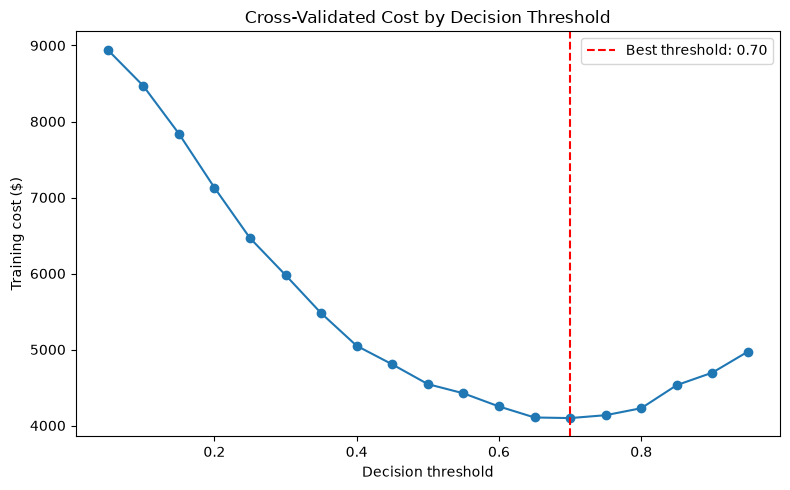

,selected result
threshold,0.7
cost,4098.0
flagged_orders,327.0
missed_late_orders,186.0


In [16]:
threshold_costs = pd.read_csv("../reports/threshold_costs.csv")
best_row = threshold_costs.loc[threshold_costs["cost"].idxmin()]

plt.figure(figsize=(8, 5))
plt.plot(
    threshold_costs["threshold"],
    threshold_costs["cost"],
    marker="o",
)
plt.axvline(
    best_row["threshold"],
    color="red",
    linestyle="--",
    label=f"Best threshold: {best_row['threshold']:.2f}",
)
plt.xlabel("Decision threshold")
plt.ylabel("Training cost ($)")
plt.title("Cross-Validated Cost by Decision Threshold")
plt.legend()
plt.tight_layout()
plt.show()

best_row.to_frame("selected result")

## Final test-set confusion matrix

The test set was evaluated once, after the model settings and threshold were fixed.

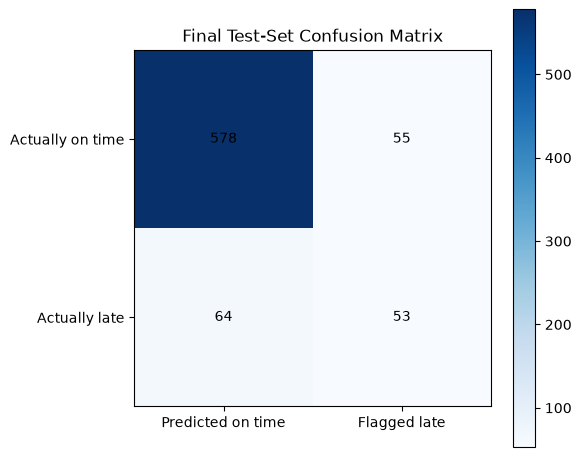

,Predicted on time,Flagged late
Actually on time,578,55
Actually late,64,53


In [17]:
metrics = json.loads(Path("../reports/metrics.json").read_text(encoding="utf-8"))

confusion = pd.DataFrame(
    metrics["confusion_matrix"],
    index=["Actually on time", "Actually late"],
    columns=["Predicted on time", "Flagged late"],
)

figure, axis = plt.subplots(figsize=(6, 5))
heatmap = axis.imshow(confusion.values, cmap="Blues")

axis.set_xticks(range(len(confusion.columns)))
axis.set_xticklabels(confusion.columns)
axis.set_yticks(range(len(confusion.index)))
axis.set_yticklabels(confusion.index)

for row_number in range(confusion.shape[0]):
    for column_number in range(confusion.shape[1]):
        axis.text(
            column_number,
            row_number,
            confusion.iloc[row_number, column_number],
            ha="center",
            va="center",
        )

axis.set_title("Final Test-Set Confusion Matrix")
figure.colorbar(heatmap)
plt.tight_layout()
plt.show()

confusion

## Cost of the three policies

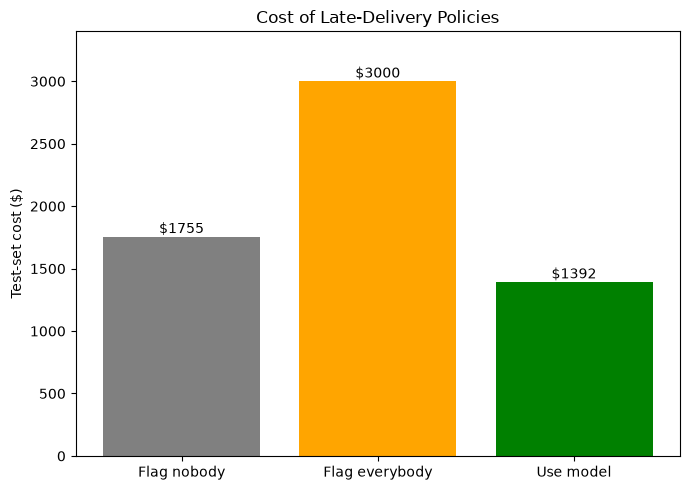

,cost
Flag nobody,1755
Flag everybody,3000
Use model,1392


In [18]:
policy_costs = pd.Series(metrics["costs"]).rename(
    {
        "flag_nobody": "Flag nobody",
        "flag_everybody": "Flag everybody",
        "model": "Use model",
    }
)

plt.figure(figsize=(7, 5))
bars = plt.bar(
    policy_costs.index,
    policy_costs.values,
    color=["gray", "orange", "green"],
)

for bar, cost in zip(bars, policy_costs.values, strict=True):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30,
        f"${cost}",
        ha="center",
    )

plt.ylabel("Test-set cost ($)")
plt.title("Cost of Late-Delivery Policies")
plt.ylim(0, max(policy_costs.values) + 400)
plt.tight_layout()
plt.show()

policy_costs.to_frame("cost")

## Recommendation

I would use this model in a controlled pilot because it reduced the test-set cost from $1,755 under the current flag-nobody policy to $1,392. The 0.70 threshold was selected because it produced the lowest cost across out-of-fold training predictions, balancing $4 vouchers against the larger $15 cost of missing a late delivery.

I excluded `order_id` because it is only an identifier, `customer_rating` because it is collected after delivery and would leak information about the outcome, and `late` because it is the target being predicted. I treated `prep_minutes` as the preparation-time field available to QuickBite when the order is placed.

The main limitation is that the data is invented and assumes every voucher works. The test recall was 45.3%, so the model still missed 64 late orders. Before full deployment, I would validate the timing and meaning of every input field and test the policy on real operational and customer-response data.